# Plot LSST light curves for solar system objects via BigQuery

The Vera C. Rubin Observatory alert archive catalogs served by the $\texttt{Pitt-Google Alert Broker}$ are currently separated into three BigQuery tables: $\texttt{alerts\_v10\_0}$, $\texttt{alerts\_v11\_0}$, and $\texttt{alerts\_v11\_1}$, as each table contains the same [schema](https://github.com/lsst/alert_packet/tree/main/python/lsst/alert/packet/schema) as the original alert bytes, excluding the fields: `cutoutScience`, `cutoutTemplate`, and `cutoutDifference`. The alert schema is used to define the data structure of the alert packet, including the name of the fields in the alert packet and the value's data type. An up-to-date list of the dataset and tables names containing LSST data are outlined in our [data listings page](https://mwvgroup.github.io/pittgoogle-client/listings.html#id4).

## Learning goals

- [Identify solar system objects in the LSST alert archive table(s)](#identify-solar-system-objects)
- [Obtain multi-band light curves of solar system objects](#obtain-photometry-ssobjects)
- [Plot multi-band light curves](#plot-light-curves)

## Prerequisites

- Complete the [One-Time Setup](https://mwvgroup.github.io/pittgoogle-client/one-time-setup/index.html), specifically:
     - Install the pittgoogle-client package
     - Setup authentication to a Google Cloud project
     - Set environment variables
     - Enable the BigQuery API
     - You can skip the command-line tools

In [1]:
import matplotlib.pyplot as plt
import pittgoogle
from matplotlib.lines import Line2D

<a id="#identify-solar-system-objects"></a>

## Identify solar system objects in the LSST alert archive table(s)

Solar system (SS) objects are designated a unique object identifier in the alert packet, referred to as `ssObjectId`. Non-SS objects have a null value for this field. The cell below returns all of the unique `ssSource.ssObjectId` values in the `alerts_v11_1` table.

In [2]:
bqclient = pittgoogle.bigquery.Client()

# construct query
sql_query = f"""
SELECT DISTINCT (ssSource.ssObjectId)
FROM
  `pitt-alert-broker.lsst.alerts_v11_1`
WHERE
  ssSource.ssObjectId IS NOT NULL  
"""

# run SQL query and inspect results
ss_object_ids = bqclient.query(query=sql_query)
ss_object_ids

,ssObjectId
0,21163628908000583
1,21164724107490138
2,21164728083624770
3,21164728169346887
4,20892032103886913
...,...
81748,21164732647419989
81749,21163645836277313
81750,21163607382831188
81751,21165814844764240


<a id="obtain-photometry-ssobjects"></a>

## Obtain multi-band light curves of solar system objects

The `psfFlux` measurements of the SS objects identified in the previous learning goal can be used to construct a multi-band light curve. In the cell below, we define a SQL query that searches for a subset of these `ssObjectId`s in each of the LSST alert archive tables served by $\texttt{Pitt-Google}$ and returns the available photometric data. Run the cells below to obtain the photometric data for five SS objects.

In [3]:
ss_object_ids_list = ss_object_ids["ssObjectId"].iloc[:5].tolist()
ss_object_ids_str = ', '.join(str(ssObjectId) for ssObjectId in ss_object_ids_list)

def select_block(version):
    """
    Build a SQL query selecting solar system detections for one schema version.

    The query reads from the table ``pitt-alert-broker.lsst.alerts_v{version}``
    and returns one row per detection for the objects listed in the
    module-level variable ``ss_object_ids_str``.

    Parameters
    ----------
    version : str
        Alert schema version, used both to pick the table name and as the
        value of the ``alertSchemaVersion`` column (e.g. ``"11_1"``).

    Returns
    -------
    str
        A SQL query string. When executed, it returns a table with the
        following columns:

        - ``ssObjectId`` : int
            Identifier of the solar system object.
        - ``psfFlux`` : float
            PSF flux, in nJy.
        - ``psfFluxErr`` : float
            Uncertainty on ``psfFlux``, in nJy.
        - ``midpointMjdTai`` : float
            Midpoint time of the exposure, in Modified Julian Date (TAI).
        - ``reliability`` : float
            Reliability score of the detection.
        - ``band`` : str
            Photometric band name (e.g. ``"g"``, ``"r"``).
        - ``alertSchemaVersion`` : str
            The ``version`` argument, repeated on every row.

    Notes
    -----
    This function reads the global variable ``ss_object_ids_str``, which must
    be a str containing a comma-separated list of ``ssObjectId`` values
    (e.g. ``"123, 456, 789"``) and must be defined before the function is
    called. The ``version`` and ``ss_object_ids_str`` values are inserted
    directly into the SQL text.
    """
    return f"""
    SELECT
      ssSource.ssObjectId,
      diaSource.psfFlux,
      diaSource.psfFluxErr,
      diaSource.midpointMjdTai,
      diaSource.reliability,
      diaSource.band,
      '{version}' AS alertSchemaVersion
    FROM `pitt-alert-broker.lsst.alerts_v{version}`
    WHERE ssSource.ssObjectId IN ({ss_object_ids_str})
    """

# construct query
sql_query = f"""
SELECT * FROM (
  {select_block('10_0')}
  UNION ALL
  {select_block('11_0')}
  UNION ALL
  {select_block('11_1')}
)
ORDER BY ssObjectId
"""

In [4]:
# run SQL query and inspect results
ss_object_light_curves = bqclient.query(query=sql_query)
ss_object_light_curves

,ssObjectId,psfFlux,psfFluxErr,midpointMjdTai,reliability,band,alertSchemaVersion
0,20892032103886913,406914.968750,1381.468750,61191.350320,1.000000,z,11_0
1,20892032103886913,699882.312500,907.433655,61228.327457,1.000000,i,11_0
2,20892032103886913,721044.062500,1123.647827,61228.351994,1.000000,z,11_0
3,20892032103886913,687908.437500,1071.861816,61228.353403,1.000000,z,11_0
4,20892032103886913,726037.375000,902.802551,61228.326103,1.000000,i,11_0
5,20892032103886913,483520.375000,722.420410,61218.297847,1.000000,i,11_0
6,20892032103886913,923773.250000,1107.239014,61235.247944,1.000000,i,11_1
7,21163628908000583,24412.511719,524.944397,61231.234293,1.000000,i,11_1
8,21163628908000583,23645.337891,511.672852,61231.233749,1.000000,i,11_1
9,21163628908000583,21701.451172,278.031403,61235.250306,1.000000,i,11_1


<a id="plot-light-curves"></a>

# Plot multi-band light curves

The previous learning goal demonstrated how to obtain the available photometric data for five SS objects by querying the LSST alert archive tables served by $\texttt{Pitt-Google}$. One of the fields returned by the query is the `reliability` field. The value of this field refers to the probability (0-1) that the detection of a difference image analysis (DIA) object is astrophysical, derived from a machine learning model. Use the cells below to plot the multi-band light curves for these five SS objects, using the reliability score to identify `psfFlux` measurements that fall below a specified threshold.

In [5]:
def plot_lc(ssObjectId, light_curve, reliability_threshold=0):
    """
    Plot a multi-band light curve for a solar system object.

    Points with reliability below ``reliability_threshold`` are drawn as open
    circles in their band's color. All others are filled circles.

    Parameters
    ----------
    ssObjectId : int
        Identifier of the solar system object, used in the plot title.
    light_curve : pandas.DataFrame
        Light curve table with one row per detection. Must contain the
        following columns:

        - ``band`` : str
            Photometric band name (e.g. ``"g"``, ``"r"``). Each unique value
            is plotted in its own color.
        - ``midpointMjdTai`` : float
            Midpoint time of the exposure, in Modified Julian Date (TAI).
        - ``psfFlux`` : float
            PSF flux, in nJy.
        - ``psfFluxErr`` : float
            Uncertainty on ``psfFlux``, in nJy.
        - ``reliability`` : float
            Reliability score of the detection, typically between 0 and 1.
    reliability_threshold : float, optional
        Points with ``reliability`` strictly below this value are drawn as
        open circles. The default of 0 draws every point as a filled circle.

    Returns
    -------
    None
        The figure is displayed with ``plt.show()``.
    """
    fig, ax = plt.subplots(figsize=(10, 5))
    handles = []

    for i, (band, df) in enumerate(light_curve.groupby("band")):
        color = f"C{i}"
        low = df.reliability < reliability_threshold

        for subset, marker_face_color in ((df[~low], color), (df[low], "none")):
            ax.errorbar(
                subset.midpointMjdTai,
                subset.psfFlux,
                yerr=subset.psfFluxErr,
                fmt="o",
                color=color,
                mfc=marker_face_color,
            )

        handles.append(Line2D([], [], marker="o", ls="none", color=color, label=band))

    handles.append(
        Line2D(
            [],
            [],
            marker="o",
            ls="none",
            color="gray",
            mfc="none",
            label=f"reliability < {reliability_threshold}",
        )
    )

    ax.set_xlabel("midpointMjdTai")
    ax.set_ylabel("psfFlux [nJy]")
    ax.set_title(f"ssObjectId {ssObjectId}")
    ax.legend(handles=handles, title="Band")
    plt.tight_layout()
    plt.show()

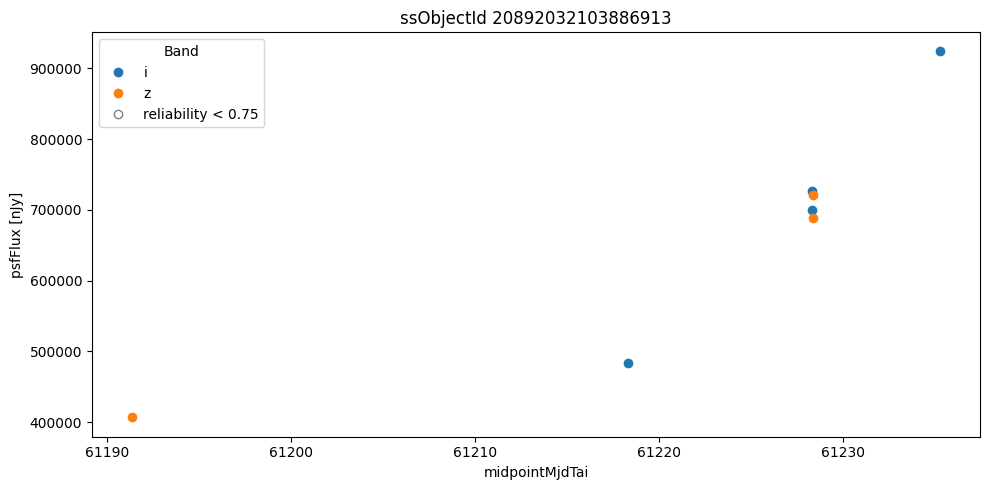

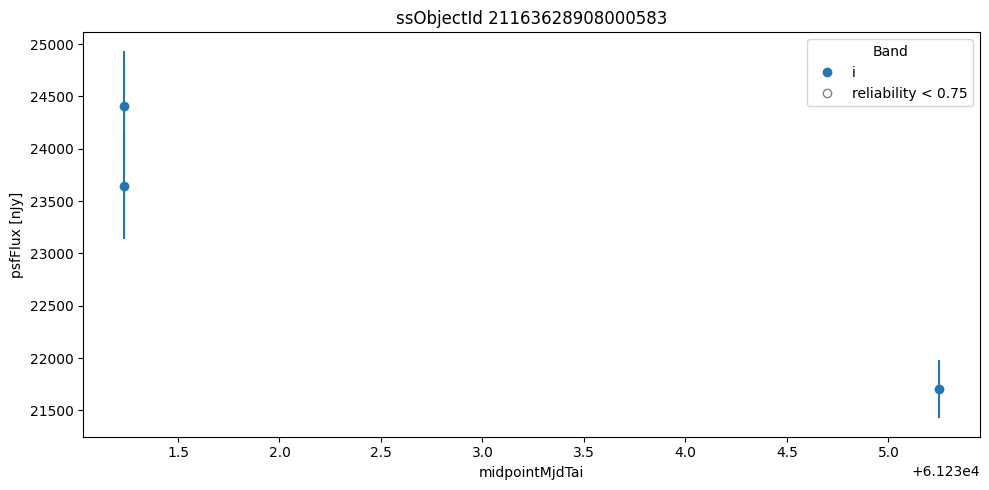

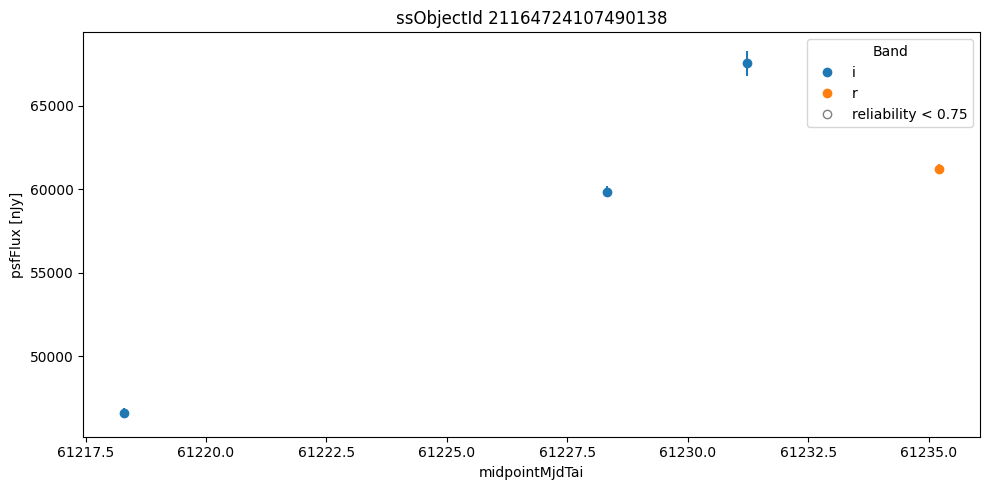

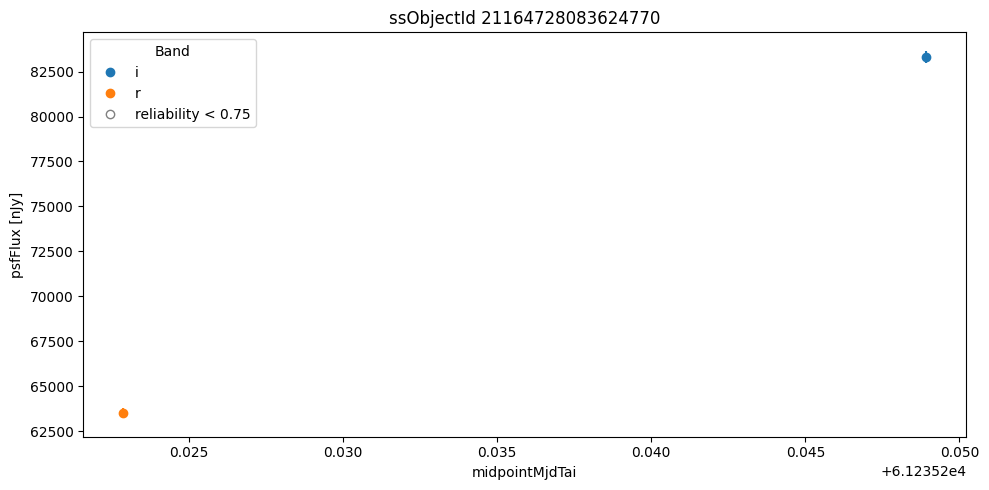

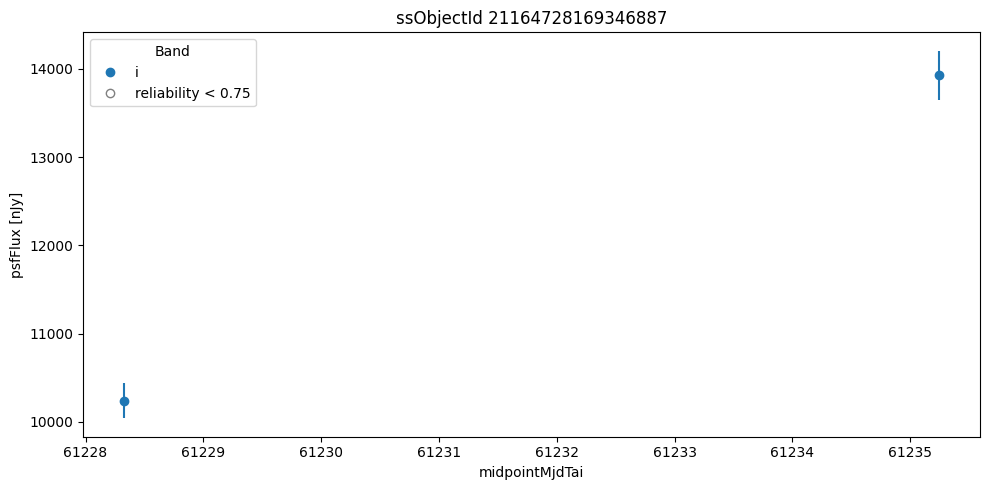

In [6]:
for ssObjectId in ss_object_light_curves.ssObjectId.unique():    
    plot_lc(
        ssObjectId=ssObjectId, 
        light_curve=ss_object_light_curves[ss_object_light_curves.ssObjectId == ssObjectId],
        reliability_threshold=0.75
    )